# TASK 3

Importy


In [50]:
import numpy as np
import matplotlib.pyplot as plt
import random
import networkx as nx

Funkcje generujące grafy

In [51]:
def assign_resistance(G):
    for u,v in G.edges():
        if 'resistance' not in G.edges[u,v]:
            G.edges[u,v]['resistance'] = random.uniform(0.1,20)
    return G
def generate_graf_ER(n=20,p=0.5):
    G = nx.erdos_renyi_graph(n=n, p=p)
    while not nx.is_connected(G):
        G = nx.erdos_renyi_graph(n=n, p=p)
    return assign_resistance(G)
def generate_graf_3regular(n):
    if n%2 != 0: n+=1
    G = nx.random_regular_graph(3,n)
    while not nx.is_connected(G):
        G = nx.random_regular_graph(3, n)
    return assign_resistance(G)
def generate_graf_bridge_connect(n1,n2,p=0.4):
    G1 = nx.erdos_renyi_graph(n1, p)
    while not nx.is_connected(G1):
        G1 = nx.erdos_renyi_graph(n1, p)
    G2 = nx.erdos_renyi_graph(n2, p)
    while not nx.is_connected(G2):
        G2 = nx.erdos_renyi_graph(n2, p)
    G = nx.disjoint_union(G1, G2)
    G.add_edge(0, n1)
    return assign_resistance(G)
def generate_graf_grid(rows,cols):
    G = nx.grid_2d_graph(rows,cols)
    G = nx.convert_node_labels_to_integers(G)
    return assign_resistance(G)
def generate_graf_world(n=20,k=4,p=0.2):
    G = nx.watts_strogatz_graph(n,k,p)
    while not nx.is_connected(G):
        G = nx.watts_strogatz_graph(n, k, p)
    return assign_resistance(G)

By obliczyć natężenia na rezystorach wykorzystamy metodę potencjałów węzłowych (I prawo Kirchhoffa). Na początku bierzemy pod uwagę Edge case z tylko dwoma wierzchołkami - liczymy z prawa Kirchhoffa bez macierzy. Następnie czas stworzyć macierze i je wypełnić. Z I prawa Kirchhoffa suma prądów musi być równa 0 oraz z prawa Ohma wiemy, że prąd płynący z węzła i do sąsiada to (Vi-Vj) * G. Uznajmy, że węzeł i ma jednego sąsiada nie będącego wierzchołkami podłączenia źródła prądu.

W takiej sytuacji równanie przedstawia się następująco

(Vi - E)*Gs + (Vi - 0)*Gt + (Vi - Vj) * Gj =0
Vi * (Gs+Gt+Gj) - Vj * Gj = E * Gs

Widzimy jak się układa nam to w macierz. W A(i)(i) mamy sumę wszystkich przewodności, w A(i,j) ujemną przewodność, a w B(i) przewodność na krawędzi (i,s) pomnożoną przez napięcie E.

Następnie mając odpowiedzi na to jakie potencjały są na danych węzłach poprzez rozwiązanie macierzy układów równań (używamy wbudowanego numpy solve, by było szybciej), możemy obliczyć natężenie na każdym oporniku R.

Ostatnią rzeczą zostało sprawdzić jakie wynik będzie w punkcie s (oddzielna pętla, by nie wdarły się przypadkiem wyniki przeciwne (s,i)!=(i,s))

Teraz tylko stworzyć graf skierowany, który wyświetlimy jako rozwiązanie układu

In [52]:
def circut_solver(G,s,t,E):
    nodes = list(G.nodes)
    other_nodes = [n for n in nodes if n!=s and n!=t]
    node_to_idx = {n: i for i, n in enumerate(other_nodes)}
    n = len(nodes) -2
    if n <=2:
        DiG = nx.DiGraph()
        DiG.add_nodes_from([s,t])
        if G.has_edge(s,t):
            R = G[s][t]
            I = E/R
            DiG.add_edge(s,t,current=I)
            I = -I
        else:
            I = 0.0
        if I>=0:
            DiG.add_edge(s,t,current=I, voltage_source=True)
        else:
            DiG.add_edge(t,s,current=-I,voltage_source=True)
        return DiG

    A = np.zeros((n,n))
    B = np.zeros(n)
    for i, node in enumerate(other_nodes):
        if node == s or node == t:continue
        sum_cond = 0.0
        for neighbour in G.neighbors(node):
            R = G[node][neighbour]['resistance']
            conductance = 1.0 / R
            if neighbour == s:
                B[i] += conductance * E
                sum_cond += conductance
            elif neighbour == t:
                sum_cond += conductance
            else:
                j = node_to_idx[neighbour]
                A[i, j] -= conductance
                sum_cond += conductance
        A[i, i] = sum_cond

    try:
        voltage_matrix = np.linalg.solve(A, B)
    except np.linalg.LinAlgError:
        raise ValueError("Macierz osobliwa, aleee jaaaak?")

    voltages = {n: 0.0 for n in nodes}
    voltages[t] = 0.0
    voltages[s] = E
    for i,node in enumerate(other_nodes):
        voltages[node] = voltage_matrix[i]

    currents = {}
    for u, v in G.edges():
        R = G[u][v]['resistance']
        voltage_u = voltages[u]
        voltage_v = voltages[v]
        current = (voltage_u - voltage_v) / R
        currents[(u, v)] = current


    ####
    DiG = nx.DiGraph()
    for u, v in G.edges():
        current = currents[(u, v)]
        if current >= 0:
            DiG.add_edge(u, v, current=abs(current))
        else:
            DiG.add_edge(v, u, current=abs(current))

    I = 0.0
    for neighbor in G.neighbors(s):
        R = G[s][neighbor]['resistance']
        current = (E - voltages[neighbor]) / R
        I += current
    I = -I
    if I >= 0:
        DiG.add_edge(s, t, current=abs(I), voltage_source=True)
    else:
        DiG.add_edge(t, s, current=abs(I), voltage_source=True)

    return DiG

Funkcja do wizualizacji grafu układu rezystorów z natężeniami

In [53]:
def visualize_graph(DiG):
    plt.figure(figsize=(14, 10))

    # Kamada-Kawai zazwyczaj o wiele lepiej układa grafy obwodów niż spring_layout
    pos = nx.kamada_kawai_layout(DiG)

    resistor_edges = []
    voltage_source_edges = []

    for u, v, d in DiG.edges(data=True):
        if d.get('voltage_source', False):
            voltage_source_edges.append((u, v))
        else:
            resistor_edges.append((u, v))

    resistor_currents = [DiG[u][v]['current'] for u, v in resistor_edges]
    vs_currents = [DiG[u][v]['current'] for u, v in voltage_source_edges]
    all_currents = resistor_currents + vs_currents

    if not all_currents:
        print("Brak prądów do narysowania.")
        return

    # Zmiana colormapy na 'plasma' (lepszy kontrast dla obwodów)
    cmap = plt.cm.plasma
    norm = plt.Normalize(min(all_currents), max(all_currents))

    is_small_graph = len(DiG) < 100
    is_micro_graph = len(DiG) <= 20

    if is_small_graph:
        nx.draw_networkx_nodes(
            DiG, pos,
            node_color='#a0c4ff',
            node_size=500,
            edgecolors='black',
            linewidths=1.5
        )
        nx.draw_networkx_labels(DiG, pos, font_size=12, font_weight='bold')

    # Rysowanie rezystorów z lekkim wygięciem (connectionstyle) zapobiega nakładaniu się krawędzi
    if resistor_edges:
        nx.draw_networkx_edges(
            DiG, pos, edgelist=resistor_edges, edge_color=resistor_currents,
            edge_cmap=cmap, edge_vmin=min(all_currents), edge_vmax=max(all_currents),
            width=2.5, arrows=True, arrowstyle='-|>', arrowsize=18,
            connectionstyle="arc3,rad=0.1"
        )

    # Rysowanie źródła napięcia (wyraźnie odznaczające się, inny kąt wygięcia)
    if voltage_source_edges:
        nx.draw_networkx_edges(
            DiG, pos, edgelist=voltage_source_edges, edge_color='#ff0055',
            width=4, arrows=True, arrowstyle='-[', arrowsize=20,
            connectionstyle="arc3,rad=-0.2"
        )

    # Etykiety prądów
    if is_micro_graph:
        edge_labels = {(u, v): f"{d['current']:.2f}A" for u, v, d in DiG.edges(data=True)}
        nx.draw_networkx_edge_labels(
            DiG, pos, edge_labels=edge_labels,
            font_size=10, font_color='black',
            bbox=dict(boxstyle="round,pad=0.3", facecolor='white', edgecolor='gray', alpha=0.9),
            rotate=False, label_pos=0.4
        )

    # Colorbar bezpośrednio przypięty do osi, aby uniknąć ostrzeżeń Matplotlib
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    ax = plt.gca()
    cbar = plt.colorbar(sm, ax=ax, shrink=0.7, pad=0.02)
    cbar.set_label('Natężenie prądu [A]', fontsize=12, fontweight='bold')

    plt.title(f"Rozpływ prądów w obwodzie (Węzły: {len(DiG)})", fontsize=16, fontweight='bold', pad=20)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

Zapis i odczyt

In [54]:
def zapis(G, filename):
    with open(filename, 'w') as f:
        for u, v, data in G.edges(data=True):
            if 'resistance' in data:
                line = f"{u} {v} {data['resistance']}\n"
                f.write(line)


def odczyt(filename):
    G = nx.Graph()
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'): continue
            try:
                u, v, resistance = line.split()
                u = int(u)
                v = int(v)
                resistance = float(resistance)

                G.add_edge(u, v, resistance=resistance)

            except ValueError as e:
                continue
    return G


### Różnice między prawem Kirchhoffa a metodą potencjałów
Wybrałem metodę potencjałów, bo jest prostsza w implementacji i bardziej intuicyjna niż metoda prawami Kirchhoffa. Druga metoda wymaga od nas znalezienia kolejnych cykli w grafie i rozpisaniu ich równań. W wyniku takiego działania dostajemy nadokreślony układ równań (n+1 równań na n niewiadomych). Żeby rozwiązać taki układ możemy wykorzystać metodę najmniejszych kwadratów, by znaleźć rozwiązanie układu.


🔹 SYMULACJA: GRAF ERDŐSA-RÉNYIEGO (ER) 🔹
Liczba węzłów: 12 | Liczba rezystorów (krawędzi): 23
Węzeł zasilania (s): 0 | Węzeł masy (t): 11 | Napięcie: 12.0V

✅ Obwód rozwiązany pomyślnie. Całkowity pobór prądu ze źródła: 1.63 A


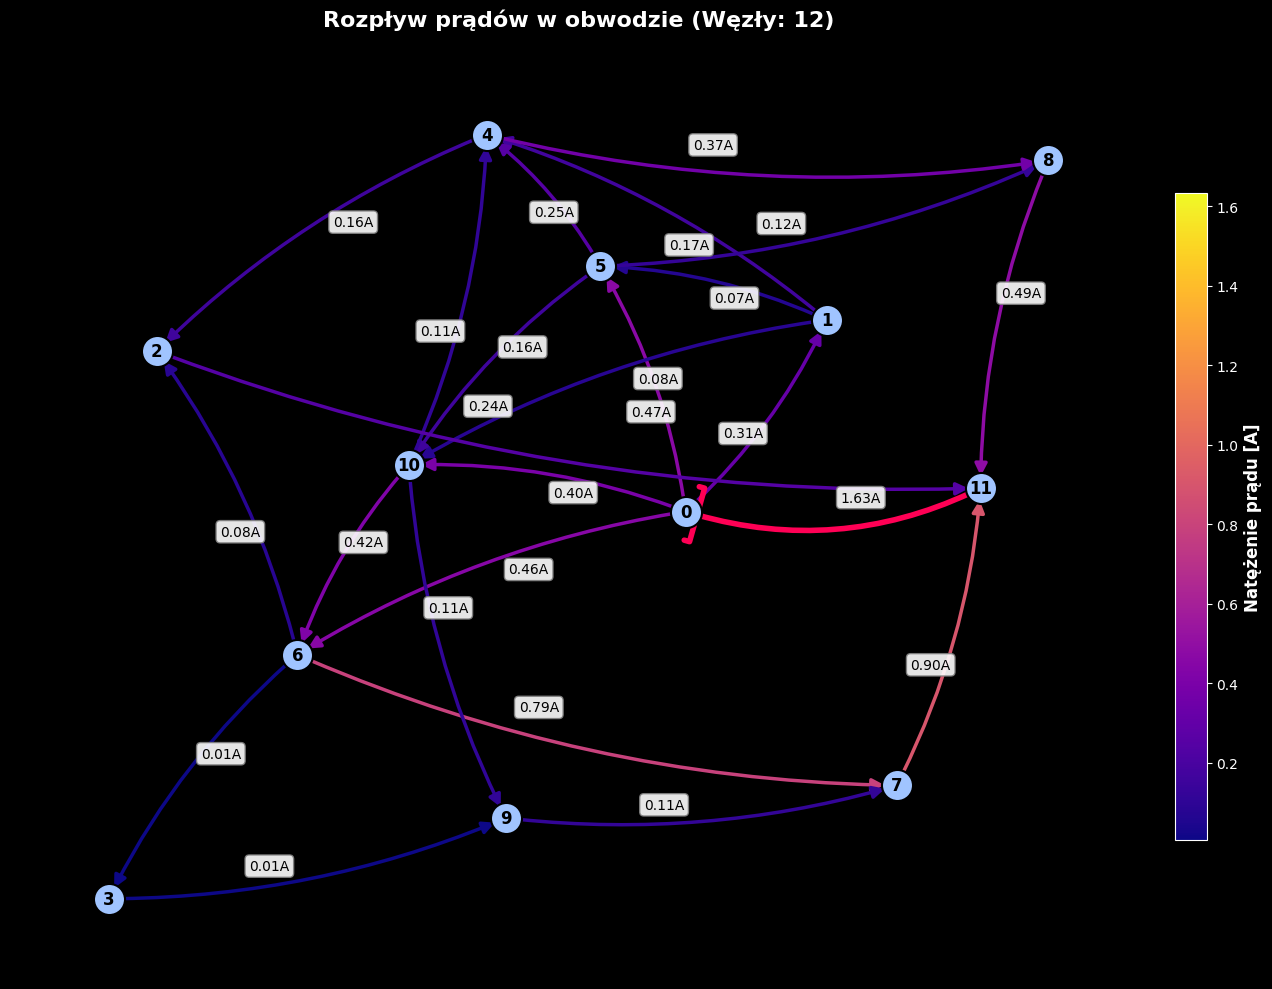


🔹 SYMULACJA: GRAF 3-REGULARNY 🔹
Liczba węzłów: 12 | Liczba rezystorów (krawędzi): 18
Węzeł zasilania (s): 0 | Węzeł masy (t): 11 | Napięcie: 12.0V

✅ Obwód rozwiązany pomyślnie. Całkowity pobór prądu ze źródła: 0.99 A


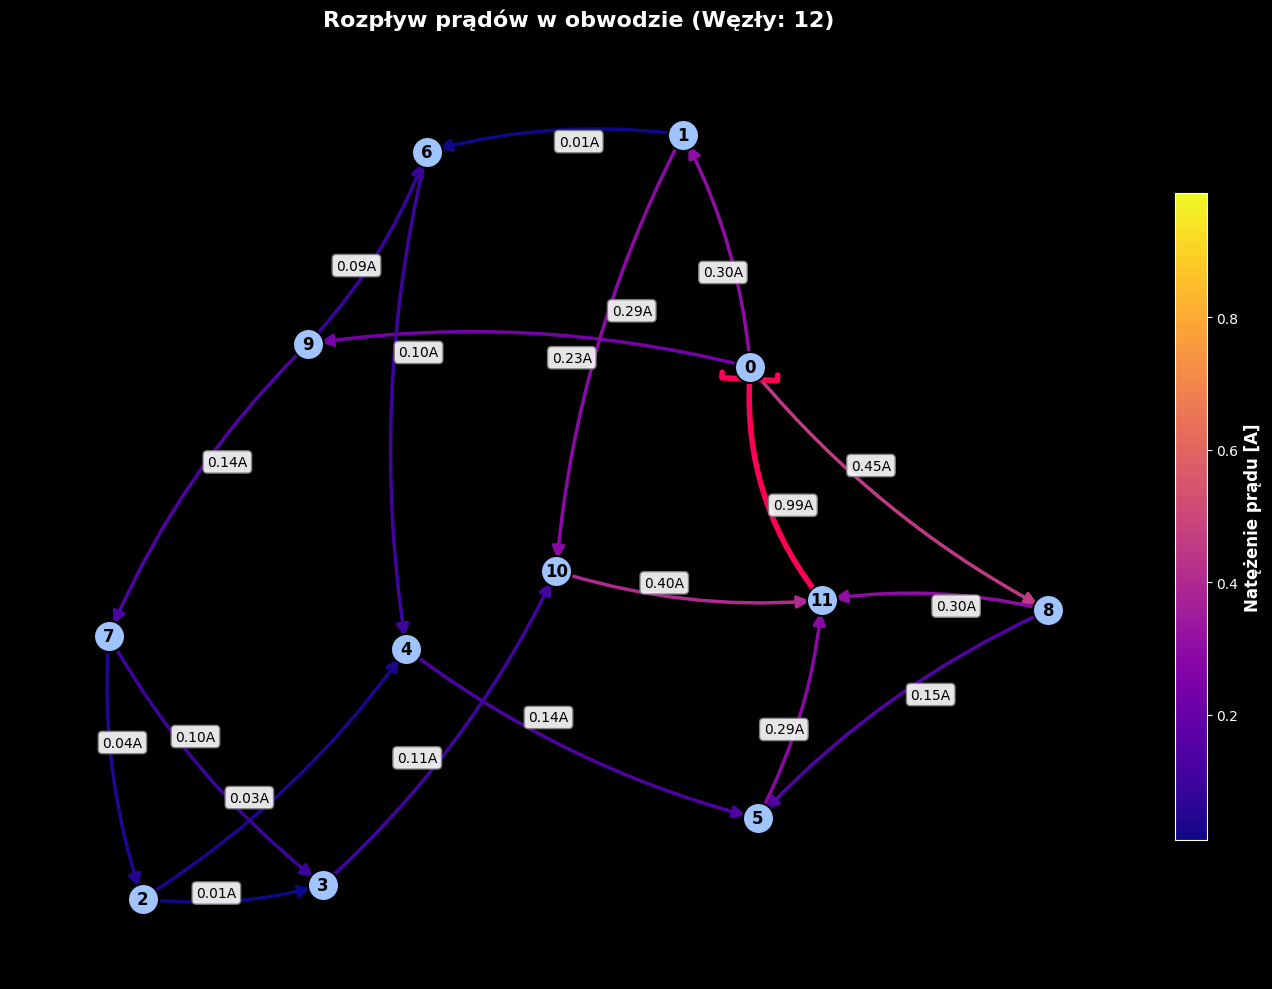


🔹 SYMULACJA: DWA GRAFY POŁĄCZONE MOSTKIEM 🔹
Liczba węzłów: 14 | Liczba rezystorów (krawędzi): 27
Węzeł zasilania (s): 0 | Węzeł masy (t): 13 | Napięcie: 12.0V

✅ Obwód rozwiązany pomyślnie. Całkowity pobór prądu ze źródła: 1.72 A


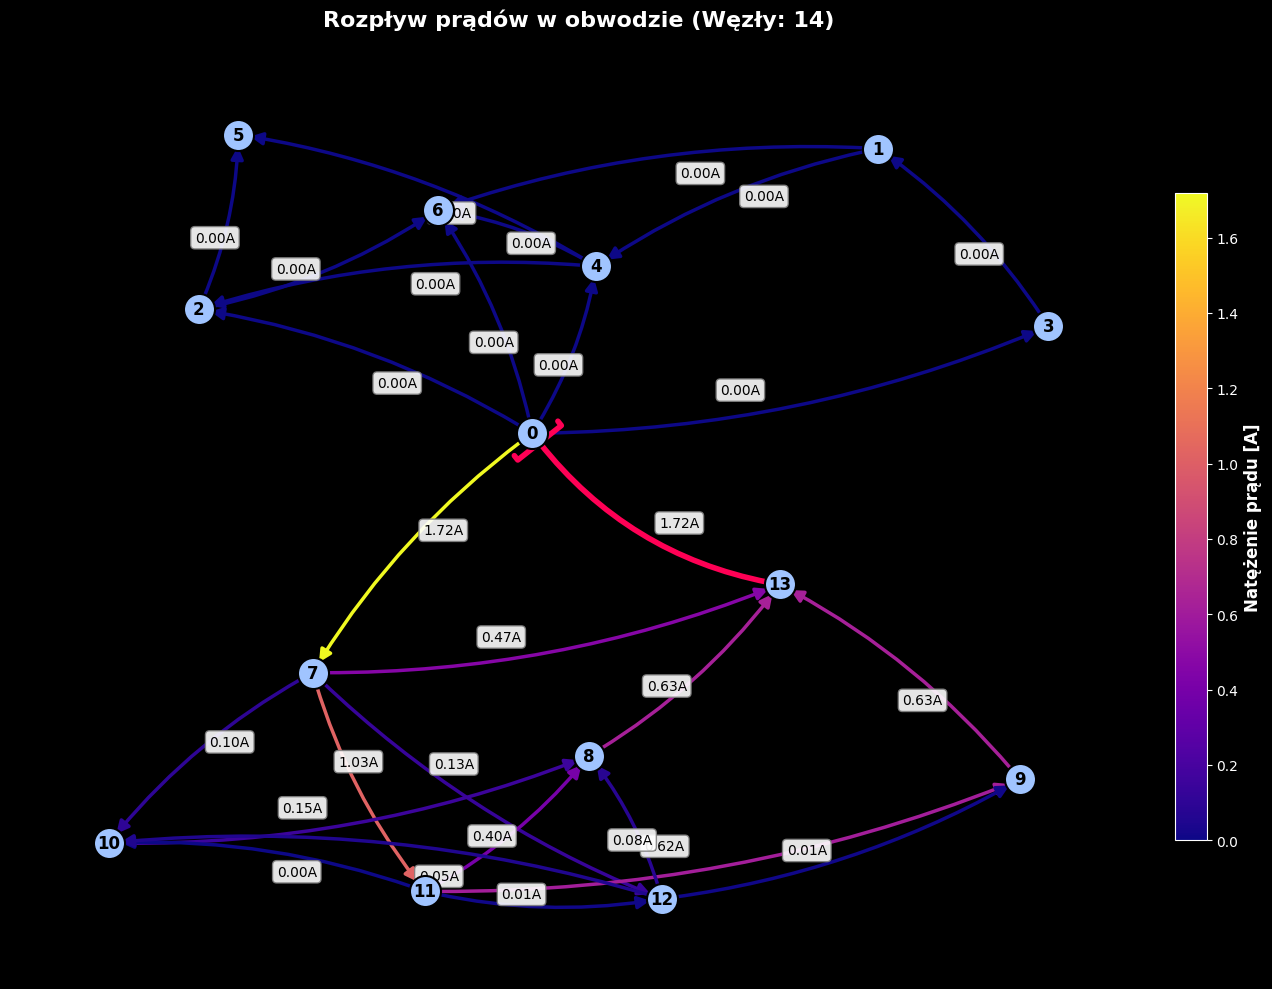


🔹 SYMULACJA: GRAF SIATKI (GRID 3X4) 🔹
Liczba węzłów: 12 | Liczba rezystorów (krawędzi): 17
Węzeł zasilania (s): 0 | Węzeł masy (t): 11 | Napięcie: 12.0V

✅ Obwód rozwiązany pomyślnie. Całkowity pobór prądu ze źródła: 0.90 A


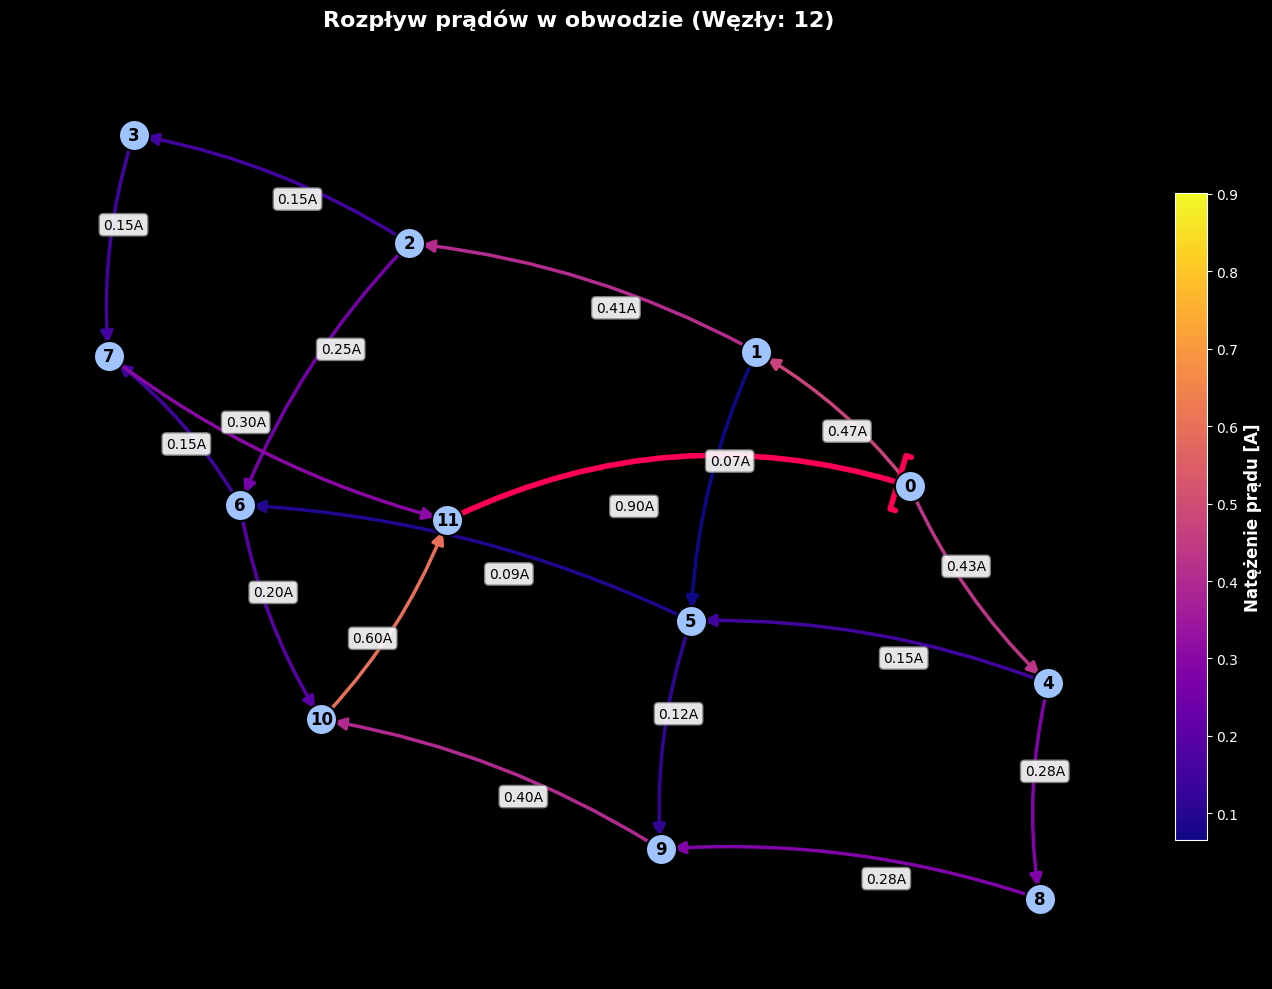


🔹 SYMULACJA: GRAF SMALL-WORLD (WATTS-STROGATZ) 🔹
Liczba węzłów: 15 | Liczba rezystorów (krawędzi): 30
Węzeł zasilania (s): 0 | Węzeł masy (t): 14 | Napięcie: 12.0V

✅ Obwód rozwiązany pomyślnie. Całkowity pobór prądu ze źródła: 4.58 A


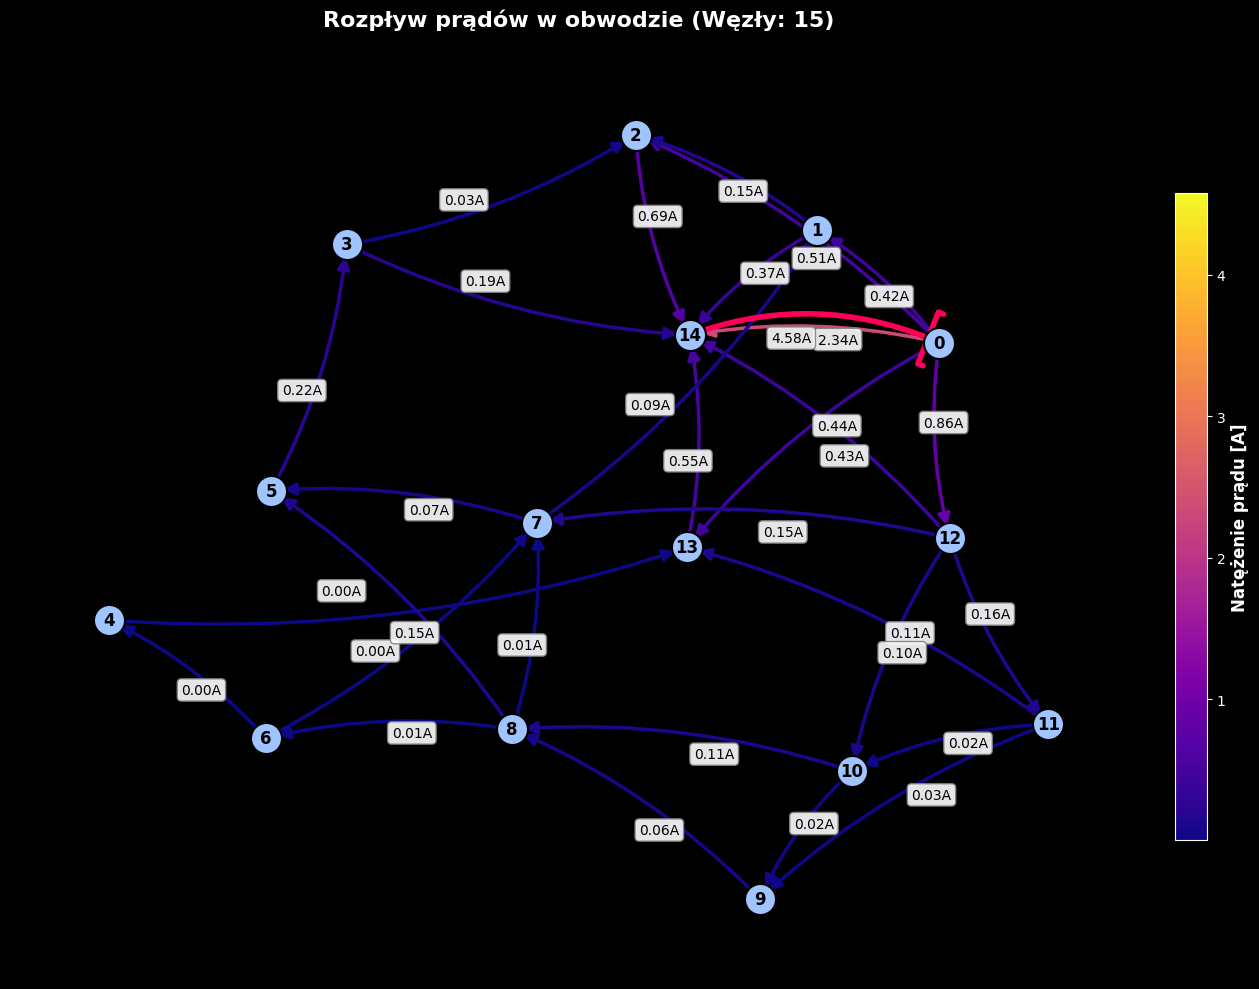

In [55]:
# Parametry symulacji
E = 12.0  # Przykładowe napięcie źródła [V]

# Zbieramy wszystkie wygenerowane grafy w słownik, aby łatwo je przeiterować.
# Ustawiamy stosunkowo małe 'n', żeby grafy były czytelne na wizualizacji (do ~20 węzłów).
test_graphs = {
    "Graf Erdősa-Rényiego (ER)": generate_graf_ER(n=12, p=0.4),
    "Graf 3-regularny": generate_graf_3regular(n=12),
    "Dwa grafy połączone mostkiem": generate_graf_bridge_connect(n1=7, n2=7, p=0.6),
    "Graf siatki (Grid 3x4)": generate_graf_grid(rows=3, cols=4),
    "Graf Small-World (Watts-Strogatz)": generate_graf_world(n=15, k=4, p=0.2)
}

for name, G in test_graphs.items():
    print(f"\n{'='*60}")
    print(f"🔹 SYMULACJA: {name.upper()} 🔹")
    print(f"{'='*60}")

    # Wybieramy węzły s i t (najprościej: pierwszy i ostatni wygenerowany węzeł)
    nodes = list(G.nodes)
    s = nodes[0]
    t = nodes[-1]

    print(f"Liczba węzłów: {len(nodes)} | Liczba rezystorów (krawędzi): {len(G.edges)}")
    print(f"Węzeł zasilania (s): {s} | Węzeł masy (t): {t} | Napięcie: {E}V\n")

    try:
        # Rozwiązanie obwodu
        DiG = circut_solver(G, s, t, E)

        # Jeżeli chcesz wyciągnąć prąd całkowity z grafu (na krawędzi s->t lub t->s)
        total_current = 0
        if DiG.has_edge(s, t) and DiG[s][t].get('voltage_source'):
            total_current = DiG[s][t]['current']
        elif DiG.has_edge(t, s) and DiG[t][s].get('voltage_source'):
            total_current = DiG[t][s]['current']

        print(f"✅ Obwód rozwiązany pomyślnie. Całkowity pobór prądu ze źródła: {total_current:.2f} A")

        # Wizualizacja
        visualize_graph(DiG)

    except Exception as e:
        print(f"❌ Wystąpił błąd podczas rozwiązywania obwodu: {e}")